In [ ]:
# ============================================================
# 00_quick_eda.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
from pathlib import Path

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용

# ── 데이터 로드
df    = load_raw()                   # 전체 32,061건
df_ao = load_raw(active_only=True)   # Active+Operating 14,399건

print(f"✅ 데이터 로드: {len(df):,}건 (Active+Oper: {len(df_ao):,}건)")
print(f"   Active+Oper 벤치마크 RevPAR: ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}")

# 📊 서울 에어비앤비 전체 데이터 개요 (Quick EDA)

**분석 목적:** 32,061개 리스팅의 전반적인 특성과 RevPAR 분포를 파악합니다.

**주요 질문:**
- 데이터 전체 구조는 어떻게 되나?
- RevPAR 분포의 특성은? (Active vs 전체)
- 어떤 서브셋으로 심층 분석할 것인가?

In [2]:
# 데이터 로드
df = pd.read_csv(CSV_PATH)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} cols")
print(f"\n주요 컬럼 현황:")
print(f"  - district 고유값: {df['district'].nunique()}개 자치구")
print(f"  - room_type 고유값: {df['room_type'].value_counts().to_dict()}")
print(f"  - refined_status: {df['refined_status'].value_counts().to_dict()}")
print(f"  - operation_status: {df['operation_status'].value_counts().to_dict()}")
print(f"\n결측치 현황:")
missing = df.isnull().sum()
print(missing[missing > 0])

Shape: 32,061 rows × 42 cols

주요 컬럼 현황:
  - district 고유값: 25개 자치구
  - room_type 고유값: {'entire_home': 21930, 'private_room': 9243, 'shared_room': 607, 'hotel_room': 281}
  - refined_status: {'Dormant': 17399, 'Active': 14399, 'Mystery': 167, 'Ghost': 88, 'New': 8}
  - operation_status: {'Operating': 28361, 'Non_Operating': 3700}

결측치 현황:
nearest_poi_addr      194
nearest_poi_image    7668
dtype: int64


## 1️⃣ RevPAR 분포 — 전체 vs Active+Operating 비교

RevPAR의 50% 이상이 0인 이유: 비활성(Dormant/Ghost) 리스팅 포함.
**분석의 실질적 대상은 Active+Operating 14,399건.**

Active+Operating: 14,399건 (44.9%)


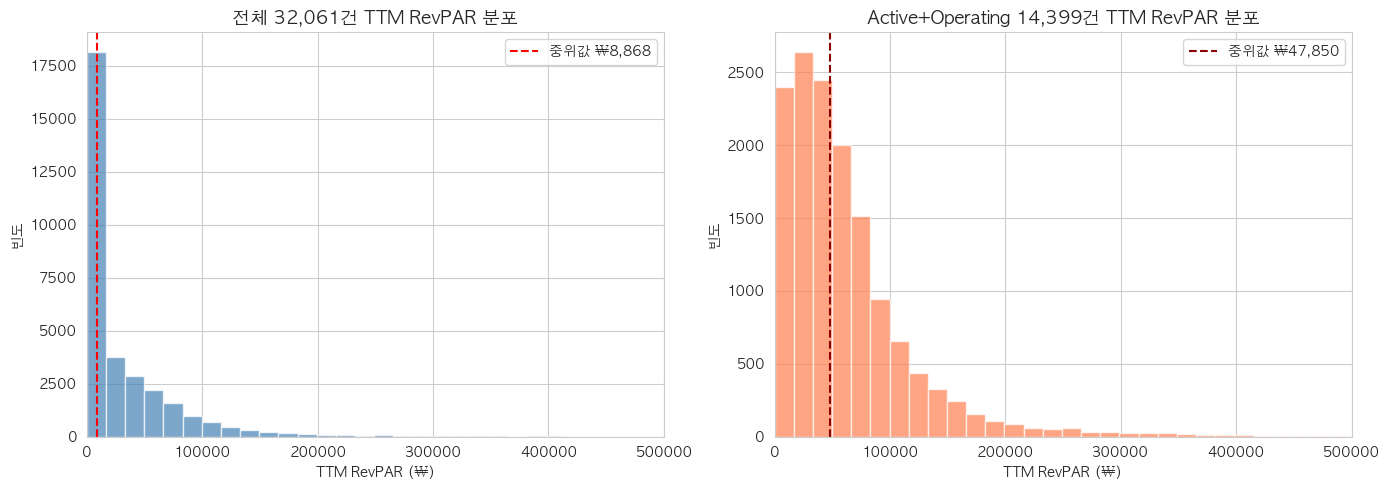


Active+Operating ttm_revpar 기술통계:
count     ₩14,399
mean      ₩63,458
std       ₩63,476
min           ₩57
25%       ₩24,096
50%       ₩47,850
75%       ₩80,229
max      ₩830,186
Name: ttm_revpar, dtype: object


In [3]:
# Active+Operating 서브셋 생성
mask_ao = (df['refined_status'] == 'Active') & (df['operation_status'] == 'Operating')
df_ao = df[mask_ao].copy()
print(f"Active+Operating: {len(df_ao):,}건 ({len(df_ao)/len(df)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 전체 RevPAR 분포
axes[0].hist(df['ttm_revpar'], bins=50, color='steelblue', alpha=0.7, edgecolor='white')
axes[0].axvline(KPI_REVPAR_ALL_MEDIAN, color='red', linestyle='--',
                label=f'중위값 ₩{KPI_REVPAR_ALL_MEDIAN:,.0f}')
axes[0].set_title('전체 32,061건 TTM RevPAR 분포', fontsize=13, fontweight='bold')
axes[0].set_xlabel('TTM RevPAR (₩)')
axes[0].set_ylabel('빈도')
axes[0].legend()
axes[0].set_xlim(0, 500000)

# Active+Operating RevPAR 분포
axes[1].hist(df_ao['ttm_revpar'], bins=50, color='coral', alpha=0.7, edgecolor='white')
axes[1].axvline(KPI_REVPAR_ACTIVE_MEDIAN, color='darkred', linestyle='--',
                label=f'중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
axes[1].set_title('Active+Operating 14,399건 TTM RevPAR 분포', fontsize=13, fontweight='bold')
axes[1].set_xlabel('TTM RevPAR (₩)')
axes[1].set_ylabel('빈도')
axes[1].legend()
axes[1].set_xlim(0, 500000)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_00_revpar_distribution.png', dpi=100, bbox_inches='tight')
plt.show()
print(f"\nActive+Operating ttm_revpar 기술통계:")
print(df_ao['ttm_revpar'].describe().apply(lambda x: f'₩{x:,.0f}'))

## 2️⃣ 리스팅 상태 구성

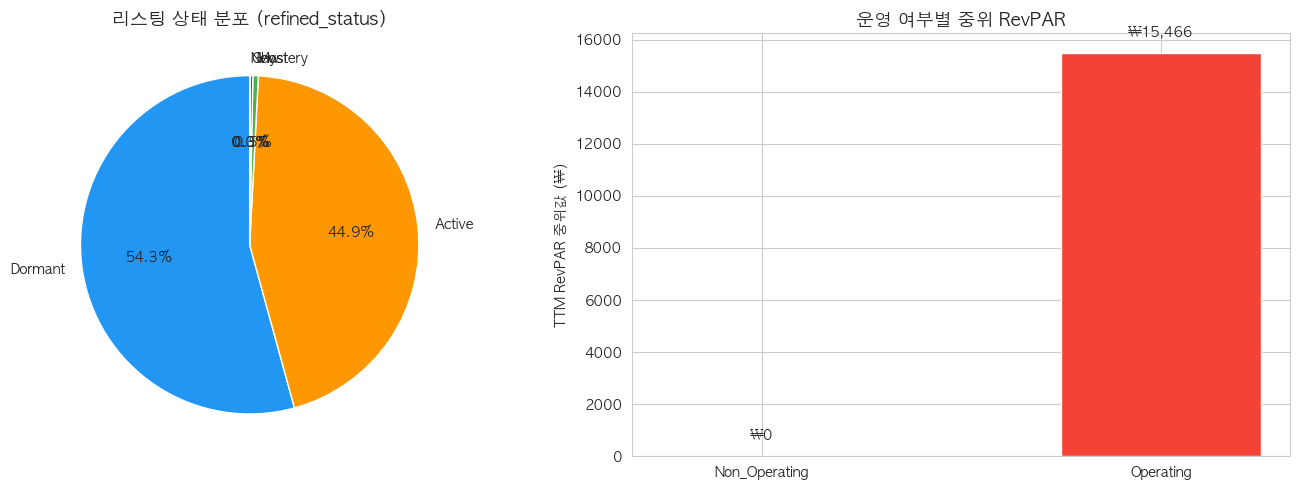

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# refined_status 파이차트
status_counts = df['refined_status'].value_counts()
colors = ['#2196F3', '#FF9800', '#4CAF50', '#9C27B0', '#F44336']
axes[0].pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%',
            colors=colors[:len(status_counts)], startangle=90)
axes[0].set_title('리스팅 상태 분포 (refined_status)', fontsize=13, fontweight='bold')

# operation_status 막대차트
op_revpar = df.groupby('operation_status')['ttm_revpar'].median()
bars = axes[1].bar(op_revpar.index, op_revpar.values, color=['#2196F3', '#F44336'], width=0.5)
axes[1].set_title('운영 여부별 중위 RevPAR', fontsize=13, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, val in zip(bars, op_revpar.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'₩{val:,.0f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_00_status_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

## 3️⃣ 자치구별 리스팅 수 및 RevPAR

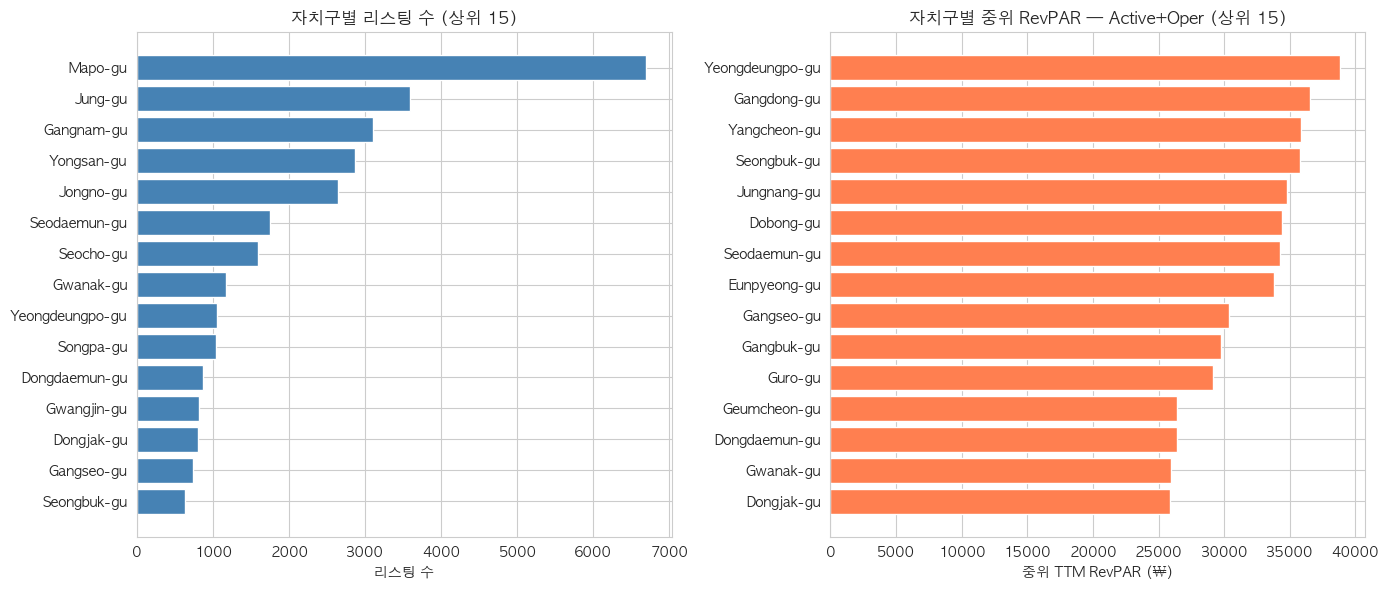


상위 5개 자치구 (RevPAR 기준, Active+Oper):
district
Mapo-gu         ₩63,366
Yongsan-gu      ₩58,083
Jongno-gu       ₩54,515
Seongdong-gu    ₩53,494
Gangnam-gu      ₩53,052
Name: ttm_revpar, dtype: object


In [5]:
# 자치구별 집계
district_stats = df.groupby('district').agg(
    listing_count=('ttm_revpar', 'count'),
    median_revpar=('ttm_revpar', 'median')
).sort_values('listing_count', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 자치구별 리스팅 수 (상위 15)
top15 = district_stats.head(15)
axes[0].barh(top15.index[::-1], top15['listing_count'][::-1], color='steelblue')
axes[0].set_title('자치구별 리스팅 수 (상위 15)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('리스팅 수')

# 자치구별 중위 RevPAR (Active+Operating)
ao_district = df_ao.groupby('district')['ttm_revpar'].median().sort_values(ascending=False)
axes[1].barh(ao_district.index[::-1][:15], ao_district.values[::-1][:15], color='coral')
axes[1].set_title('자치구별 중위 RevPAR — Active+Oper (상위 15)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('중위 TTM RevPAR (₩)')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_00_district_overview.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n상위 5개 자치구 (RevPAR 기준, Active+Oper):")
print(ao_district.head(5).apply(lambda x: f'₩{x:,.0f}'))

## 4️⃣ 데이터 품질 요약

**분석 준비 완료 확인:**
- ✅ 결측치: `nearest_poi_image`만 23.9% (분석 제외)
- ✅ 중복: 0건
- ✅ 이상치 제거 완료 (`_final.ipynb`에서 처리)

In [6]:
print("="*50)
print("📋 데이터 품질 요약")
print("="*50)
print(f"  전체 리스팅: {len(df):,}건")
print(f"  분석 대상 (Active+Oper): {len(df_ao):,}건 ({len(df_ao)/len(df)*100:.1f}%)")
print(f"  비활성 (Dormant/Ghost): {(df['refined_status'].isin(['Dormant','Ghost'])).sum():,}건")
print(f"  자치구 수: {df['district'].nunique()}개")
print(f"  room_type 유형: {df['room_type'].nunique()}개")
print(f"\n  ttm_revpar 분포 (전체):")
print(f"    0원 비율: {(df['ttm_revpar']==0).mean()*100:.1f}%")
print(f"    중위값: ₩{df['ttm_revpar'].median():,.0f}")
print(f"    상위 25%: ₩{df['ttm_revpar'].quantile(0.75):,.0f}")
print(f"\n  ttm_revpar 분포 (Active+Oper):")
print(f"    중위값: ₩{df_ao['ttm_revpar'].median():,.0f}")
print(f"    평균: ₩{df_ao['ttm_revpar'].mean():,.0f}")
print(f"    상위 25%: ₩{df_ao['ttm_revpar'].quantile(0.75):,.0f}")
print("="*50)

📋 데이터 품질 요약
  전체 리스팅: 32,061건
  분석 대상 (Active+Oper): 14,399건 (44.9%)
  비활성 (Dormant/Ghost): 17,487건
  자치구 수: 25개
  room_type 유형: 4개

  ttm_revpar 분포 (전체):
    0원 비율: 37.1%
    중위값: ₩8,868
    상위 25%: ₩45,260

  ttm_revpar 분포 (Active+Oper):
    중위값: ₩47,850
    평균: ₩63,458
    상위 25%: ₩80,229
